In [ ]:

!pip install -q datasets pandas

from datasets import load_dataset

ds = load_dataset("fancyzhx/ag_news")

print(ds)


README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [ ]:

# Check dataset splits
print("Training samples:", len(ds["train"]))
print("Testing samples:", len(ds["test"]))

# Check available columns
print("\nColumns:", ds["train"].column_names)

# Check category names
class_names = ds["train"].features["label"].names
print("\nCategories:", class_names)

# Display one sample
print("\nSample:")
print(ds["train"][0])


Training samples: 120000
Testing samples: 7600

Columns: ['text', 'label']

Categories: ['World', 'Sports', 'Business', 'Sci/Tech']

Sample:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [ ]:

import pandas as pd

train_df = ds["train"].to_pandas()
test_df = ds["test"].to_pandas()

# Convert numerical labels into category names
train_df["category"] = train_df["label"].map(
    dict(enumerate(class_names))
)

test_df["category"] = test_df["label"].map(
    dict(enumerate(class_names))
)

print(train_df.head())
print("\nDataset shape:", train_df.shape)


                                                text  label  category
0  Wall St. Bears Claw Back Into the Black (Reute...      2  Business
1  Carlyle Looks Toward Commercial Aerospace (Reu...      2  Business
2  Oil and Economy Cloud Stocks' Outlook (Reuters...      2  Business
3  Iraq Halts Oil Exports from Main Southern Pipe...      2  Business
4  Oil prices soar to all-time record, posing new...      2  Business

Dataset shape: (120000, 3)


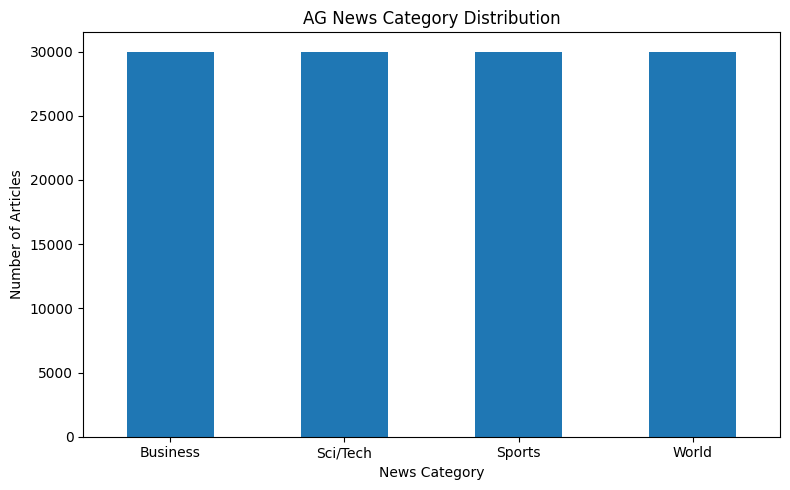

In [ ]:

import matplotlib.pyplot as plt

train_df["category"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("AG News Category Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

X_train = train_df["text"]
y_train = train_df["label"]

X_test = test_df["text"]
y_test = test_df["label"]

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        stop_words="english",
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        C=4
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


Accuracy: 92.22 %

Classification Report:

              precision    recall  f1-score   support

       World       0.93      0.91      0.92      1900
      Sports       0.96      0.98      0.97      1900
    Business       0.90      0.89      0.89      1900
    Sci/Tech       0.90      0.90      0.90      1900

    accuracy                           0.92      7600
   macro avg       0.92      0.92      0.92      7600
weighted avg       0.92      0.92      0.92      7600



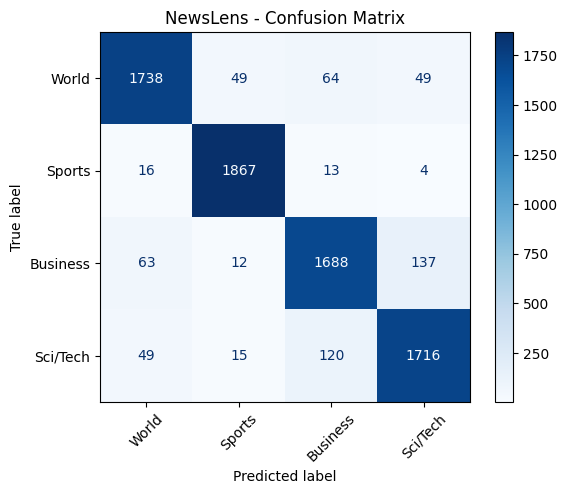

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("NewsLens - Confusion Matrix")
plt.show()


In [ ]:

def predict_news(news):
    prediction = model.predict([news])[0]
    probabilities = model.predict_proba([news])[0]

    print("Predicted Category:", class_names[prediction])
    print("Confidence:", round(max(probabilities) * 100, 2), "%")

predict_news(
    "Apple announces a new artificial intelligence chip for its devices."
)


Predicted Category: Sci/Tech
Confidence: 87.66 %


In [ ]:

!pip install -q sentence-transformers faiss-cpu


In [ ]:

from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

news_sample = train_df.sample(
    n=5000,
    random_state=42
).reset_index(drop=True)

texts = news_sample["text"].tolist()

embeddings = embedding_model.encode(
    texts,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Embedding shape:", embeddings.shape)
print("Embeddings generated successfully!")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Embedding shape: (5000, 384)
Embeddings generated successfully!


In [ ]:

from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

news_sample["cluster"] = kmeans.fit_predict(embeddings)

print("Clustering completed!")
print(news_sample["cluster"].value_counts())


Clustering completed!
cluster
1    1412
3    1377
0    1110
2    1101
Name: count, dtype: int64


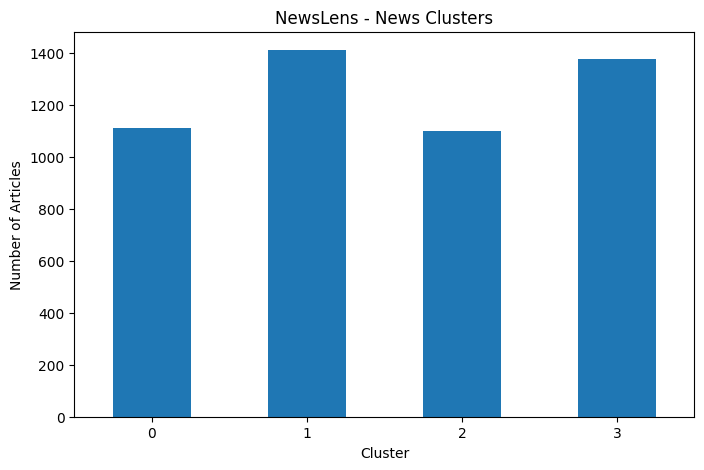

In [ ]:

import matplotlib.pyplot as plt

news_sample["cluster"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("NewsLens - News Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.show()


In [ ]:

import faiss
import numpy as np

embedding_array = np.asarray(
    embeddings,
    dtype="float32"
)

dimension = embedding_array.shape[1]

index = faiss.IndexFlatIP(dimension)
index.add(embedding_array)

print("FAISS index created!")
print("Total indexed articles:", index.ntotal)


FAISS index created!
Total indexed articles: 5000


In [ ]:

def search_news(query, top_k=5):

    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype="float32"
    )

    scores, indices = index.search(query_embedding, top_k)

    for rank, idx in enumerate(indices[0]):
        print(f"\nResult {rank + 1}")
        print("Similarity:", round(float(scores[0][rank]), 3))
        print("Category:", news_sample.iloc[idx]["category"])
        print("News:", news_sample.iloc[idx]["text"])


search_news("Latest developments in artificial intelligence")



Result 1
Similarity: 0.389
Category: Sci/Tech
News: NASA Software Allows Satellites to Troubleshoot in Space Goddard Space Flight Center -- NASA scientists recently successfully radioed artificial intelligence (AI) software to a satellite. They tested the software's ability to find and analyze errors in the spacecraft's systems...

Result 2
Similarity: 0.36
Category: Sci/Tech
News: Rise of the Robots: Segway Platform Gives Mechanoids Motion (SPACE.com) SPACE.com - A military project aimed at building smarter robots has given researchers the wheels they need to make their automatons go.

Result 3
Similarity: 0.339
Category: Sci/Tech
News: Tech 2005: What's New and  What's Next The products you use are about to get smarter, faster, smaller, cheaper, and more colorful. Here's your guide to what's ahead in PCs, software, mobile gadgets, home electronics, and more.

Result 4
Similarity: 0.299
Category: Sci/Tech
News: Intel sees big changes to the net The net must be changed to help it cope

In [ ]:

import joblib
import os

os.makedirs("newslens", exist_ok=True)

joblib.dump(model, "newslens/news_classifier.pkl")
joblib.dump(embedding_model, "newslens/embedding_model.pkl")
joblib.dump(kmeans, "newslens/kmeans_model.pkl")

np.save("newslens/news_embeddings.npy", embedding_array)

news_sample.to_pickle("newslens/news_data.pkl")

faiss.write_index(index, "newslens/news_index.faiss")

print("All models and data saved successfully!")


All models and data saved successfully!


In [ ]:

!pip install -q streamlit pyngrok


In [ ]:

%%writefile app.py

import streamlit as st
import joblib
import pandas as pd
import numpy as np
import faiss

st.set_page_config(
    page_title="NewsLens",
    page_icon="📰",
    layout="wide"
)

@st.cache_resource
def load_resources():
    model = joblib.load("newslens/news_classifier.pkl")
    embedding_model = joblib.load("newslens/embedding_model.pkl")
    data = pd.read_pickle("newslens/news_data.pkl")
    index = faiss.read_index("newslens/news_index.faiss")
    return model, embedding_model, data, index

model, embedding_model, news_data, index = load_resources()

class_names = ["World", "Sports", "Business", "Sci/Tech"]

st.title("NewsLens")
st.subheader("AI-Powered News Intelligence System")

st.write(
    "Classify news articles, discover similar stories "
    "and explore hidden patterns in news data."
)

tab1, tab2, tab3 = st.tabs([
    "News Classification",
    "Semantic Search",
    "News Analytics"
])

# TAB 1: CLASSIFICATION

with tab1:
    st.header("News Category Prediction")

    news_text = st.text_area(
        "Enter a news article",
        height=150,
        placeholder="Paste your news article here..."
    )

    if st.button("Predict Category"):
        if news_text.strip():

            prediction = model.predict([news_text])[0]
            probabilities = model.predict_proba([news_text])[0]

            st.success(
                f"Predicted Category: {class_names[prediction]}"
            )

            st.metric(
                "Prediction Confidence",
                f"{max(probabilities) * 100:.2f}%"
            )

            probability_df = pd.DataFrame({
                "Category": class_names,
                "Probability": probabilities
            })

            st.bar_chart(
                probability_df.set_index("Category")
            )

        else:
            st.warning("Please enter a news article.")

# TAB 2: SEMANTIC SEARCH

with tab2:
    st.header("Find Similar News Articles")

    query = st.text_input(
        "Enter a topic or news query",
        placeholder="Example: Artificial intelligence developments"
    )

    top_k = st.slider("Number of results", 1, 10, 5)

    if st.button("Search News"):
        if query.strip():

            query_embedding = embedding_model.encode(
                [query],
                normalize_embeddings=True
            )

            query_embedding = np.asarray(
                query_embedding,
                dtype="float32"
            )

            scores, indices = index.search(
                query_embedding,
                top_k
            )

            for rank, idx in enumerate(indices[0]):

                article = news_data.iloc[idx]

                st.markdown(f"### Result {rank + 1}")

                st.write(article["text"])

                st.caption(
                    f"Category: {article['category']} | "
                    f"Similarity: {scores[0][rank]:.3f}"
                )

                st.divider()

        else:
            st.warning("Please enter a search query.")

# TAB 3: ANALYTICS

with tab3:
    st.header("News Dataset Analytics")

    col1, col2 = st.columns(2)

    with col1:
        st.metric("Indexed Articles", len(news_data))

    with col2:
        st.metric(
            "News Categories",
            news_data["category"].nunique()
        )

    st.subheader("Category Distribution")

    st.bar_chart(
        news_data["category"].value_counts()
    )

    st.subheader("K-Means Cluster Distribution")

    st.bar_chart(
        news_data["cluster"].value_counts().sort_index()
    )

    st.subheader("Sample News Articles")

    st.dataframe(
        news_data[["text", "category", "cluster"]].head(20),
        use_container_width=True
    )

st.sidebar.title("About NewsLens")

st.sidebar.write(
    "An ML-based news intelligence platform "
    "built using NLP, machine learning and semantic search."
)

st.sidebar.markdown(
    "**Technologies:** TF-IDF, Logistic Regression, "
    "Sentence Transformers, K-Means, FAISS and Streamlit"
)


Writing app.py


In [ ]:
from pyngrok import ngrok
import subprocess
import time

# Add your ngrok authentication token first
# https://dashboard.ngrok.com/get-started/your-authtoken

!ngrok config add-authtoken 3IEXKRjt2IHiE1Lb00155GWBSzW_7sHLxoWDj6kF91FAVeq9t

process = subprocess.Popen([
    "streamlit", "run", "app.py",
    "--server.port", "8501",
    "--server.address", "0.0.0.0"
])

time.sleep(5)

public_url = ngrok.connect(8501)
print("NewsLens Dashboard:", public_url)

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml
NewsLens Dashboard: NgrokTunnel: "https://jogging-unkind-euphemism.ngrok-free.dev" -> "http://localhost:8501"
